# Parte 4: Clusters no mapa e outliers
**Responsável:** Ruan · Projeto final de Aprendizado Não Supervisionado (SOM)

**Objetivo desta etapa:** agrupar os neurônios do SOM em clusters, atribuir a cada cliente o cluster do seu neurônio vencedor,
identificar os outliers e salvar `dados/clusters.csv` para as Partes 5 e 6.

**Por que agrupar os neurônios e não os clientes:** os 100 neurônios já são uma versão "resumida e suavizada" dos 440 clientes.
Clusterizar os pesos é a abordagem clássica em duas etapas (primeiro o SOM, depois o K-Means). Ela reduz o efeito de ruído e garante que cada
cluster seja uma **região do mapa**.

## 1. Bibliotecas, dados e mapa

In [1]:
import os, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from minisom import MiniSom

SEED = 42
np.random.seed(SEED)

# Paleta do projeto (a mesma da Parte 1)
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#52514e"
COR_CANAL = {"Horeca": AZUL, "Varejo": LARANJA}
DIVERGENTE = LinearSegmentedColormap.from_list("div", ["#d95926", "#f0efec", "#2a78d6"])
# Clusters: cores diferentes das do canal, para não confundir "cluster" com "Horeca/Varejo"
COR_CLUSTER = ["#1baf7a", "#6250d6", "#eda100"]          # aqua, violeta, amarelo
MARCA_CLUSTER = ["o", "s", "^"]
CINZAS = LinearSegmentedColormap.from_list("cinzas", ["#f4f4f2", "#52514e"])   # U-Matrix: escuro = distância maior

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.edgecolor": "#888", "axes.labelcolor": "#222", "xtick.color": "#444", "ytick.color": "#444",
})
os.makedirs("figuras", exist_ok=True)

GASTOS = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
X_scaled = pd.read_csv("dados/X_scaled.csv").values
df = pd.read_csv("dados/dados_preprocessados.csv")
print("X_scaled:", X_scaled.shape, "| df:", df.shape)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X_scaled: (440, 6) | df: (440, 16)


In [2]:
# Mapa treinado na Parte 2 (Roger)
try:
    with open("dados/som.pkl", "rb") as f:
        som = pickle.load(f)
except Exception as erro_pickle:
    # Plano B: se o pickle não abrir (versão diferente de numpy/minisom), recria o mapa a partir dos pesos salvos
    print("som.pkl não abriu, recriando a partir de dados/som_pesos.npy:", erro_pickle)
    som = MiniSom(10, 10, X_scaled.shape[1], sigma=2.0, learning_rate=0.3, random_seed=SEED)
    som._weights = np.load("dados/som_pesos.npy")

LADO = som.get_weights().shape[0]
bmu = np.array([som.winner(x) for x in X_scaled])          # neurônio vencedor (BMU) de cada cliente
print("Mapa:", som.get_weights().shape, "| QE:", round(som.quantization_error(X_scaled), 4),
      "| TE:", round(som.topographic_error(X_scaled), 4))

def eixo_mapa(ax, titulo=""):
    """Padroniza um eixo de mapa: x = 1º índice do neurônio, y = 2º índice (mesma convenção de som.winner)."""
    ax.set_xlim(0, LADO); ax.set_ylim(0, LADO); ax.set_aspect("equal")
    ax.set_xticks(np.arange(LADO) + 0.5); ax.set_xticklabels(range(LADO))
    ax.set_yticks(np.arange(LADO) + 0.5); ax.set_yticklabels(range(LADO))
    ax.grid(False); ax.tick_params(length=0, labelsize=8)
    ax.set_xlabel("x (bmu_x)"); ax.set_ylabel("y (bmu_y)")
    if titulo: ax.set_title(titulo)

Mapa: (10, 10, 6) | QE: 0.8977 | TE: 0.05


## 2. Escolha do k (cotovelo e silhouette, k = 2 a 6)
- **Cotovelo:** a inércia (soma das distâncias ao centróide) sempre cai quando k aumenta. Procuramos o ponto em que ela
  **para de cair muito**.
- **Silhouette:** de −1 a 1. Mede o quanto cada ponto está mais perto do próprio cluster do que do vizinho. Quanto maior, melhor.
  Calculamos sobre os pesos dos neurônios, que é onde o K-Means roda, e também sobre os clientes.

In [3]:
pesos = som.get_weights().reshape(-1, X_scaled.shape[1])          # 100 neurônios × 6
idx_bmu = bmu[:, 0] * LADO + bmu[:, 1]                             # índice do BMU de cada cliente na lista de pesos

linhas = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(pesos)
    rot_clientes = km.labels_[idx_bmu]
    linhas.append({"k": k, "inercia": km.inertia_,
                   "silhouette_neuronios": silhouette_score(pesos, km.labels_),
                   "silhouette_clientes": silhouette_score(X_scaled, rot_clientes),
                   "tamanhos": np.bincount(rot_clientes, minlength=k).tolist()})
escolha_k = pd.DataFrame(linhas)
escolha_k["queda_inercia"] = -escolha_k["inercia"].diff()
escolha_k.round(3)

,k,inercia,silhouette_neuronios,silhouette_clientes,tamanhos,queda_inercia
0,2,258.937,0.331,0.266,"[213, 227]",NaN
1,3,198.130,0.304,0.224,"[203, 93, 144]",60.806
2,4,168.819,0.253,0.190,"[181, 115, 59, 85]",29.311
3,5,146.830,0.269,0.197,"[44, 172, 64, 122, 38]",21.990
4,6,126.660,0.276,0.186,"[162, 101, 35, 50, 56, 36]",20.170


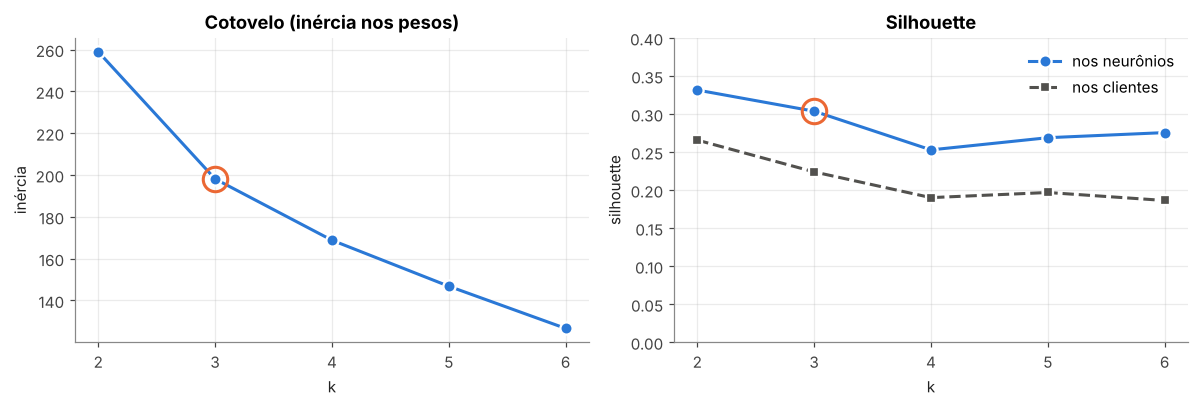

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.plot(escolha_k["k"], escolha_k["inercia"], "-o", color=AZUL, lw=2, ms=8, mec="white", mew=1.5)
ax.plot(3, escolha_k.loc[escolha_k.k == 3, "inercia"].item(), "o", ms=16, mfc="none", mec=LARANJA, mew=2)
ax.set_title("Cotovelo (inércia nos pesos)"); ax.set_xlabel("k"); ax.set_ylabel("inércia"); ax.set_xticks(range(2, 7))
ax = axes[1]
ax.plot(escolha_k["k"], escolha_k["silhouette_neuronios"], "-o", color=AZUL, lw=2, ms=8, mec="white", mew=1.5,
        label="nos neurônios")
ax.plot(escolha_k["k"], escolha_k["silhouette_clientes"], "--s", color=CINZA, lw=2, ms=7, mec="white", mew=1.5,
        label="nos clientes")
ax.plot(3, escolha_k.loc[escolha_k.k == 3, "silhouette_neuronios"].item(), "o", ms=16, mfc="none", mec=LARANJA, mew=2)
ax.set_title("Silhouette"); ax.set_xlabel("k"); ax.set_ylabel("silhouette"); ax.set_xticks(range(2, 7)); ax.set_ylim(0, 0.4)
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("figuras/04_escolha_k.png", bbox_inches="tight"); plt.show()

**Leitura e decisão:**
- **Cotovelo em k = 3:** a inércia cai cerca de 61 de k = 2 para k = 3 e só cerca de 29 de k = 3 para k = 4. Depois as quedas ficam parecidas (≈ 20).
- **O silhouette favorece k = 2 (0,331), mas por pouco:** k = 3 tem 0,304, uma diferença de 0,027. De k = 4 em diante ele cai para ≈ 0,25.
- **Os silhouettes são baixos em todos os k** (≤ 0,33 nos neurônios, ≤ 0,27 nos clientes). Isso confirma o que a U-Matrix mostrou:
  os clientes formam um **contínuo**, sem grupos bem separados. Qualquer k é uma partição de um gradiente; não há "ilhas"
  naturais para descobrir. Isso precisa estar no relatório como limitação.
- **Escolha: k = 3.** É o cotovelo, o silhouette fica a 0,03 do máximo, e o k = 2 praticamente reproduz o `Channel` (que já
  conhecemos). O k = 3 separa um terceiro grupo que o canal sozinho não mostra (ver o perfil abaixo e a Parte 6).

## 3. Clusters no mapa

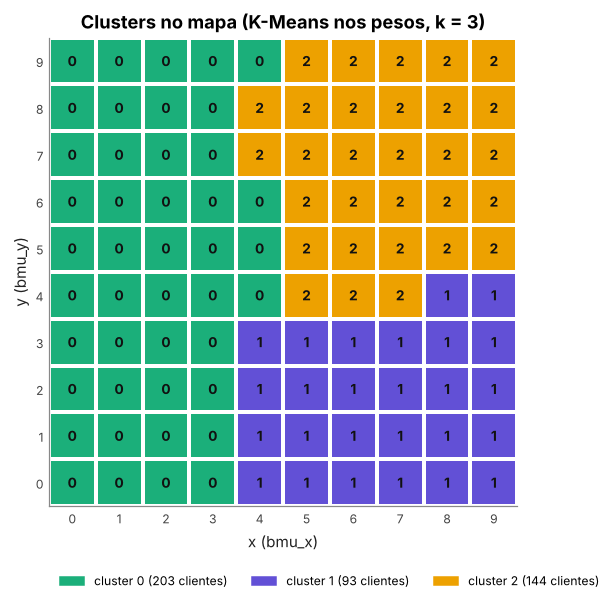

Centróides (z-score) e composição:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,clientes,% Varejo
0,0.02,-0.80,-0.81,0.06,-0.76,-0.32,203,1%
1,-0.83,0.51,0.68,-0.95,0.81,-0.53,93,68%
2,0.43,0.63,0.59,0.35,0.51,0.63,144,53%


In [5]:
K = 3
km = KMeans(n_clusters=K, random_state=SEED, n_init=10).fit(pesos)
cluster_neuronio = km.labels_.reshape(LADO, LADO)          # [x, y]
cluster = km.labels_[idx_bmu]                              # cluster de cada cliente = cluster do seu BMU

fig, ax = plt.subplots(figsize=(6.4, 5.6))
ax.pcolormesh(cluster_neuronio.T, cmap=ListedColormap(COR_CLUSTER), vmin=-0.5, vmax=K - 0.5,
              edgecolors="white", linewidth=1.5)
for x in range(LADO):
    for y in range(LADO):
        ax.text(x + 0.5, y + 0.5, cluster_neuronio[x, y], ha="center", va="center", fontsize=9, color="#111", fontweight="bold")
eixo_mapa(ax, f"Clusters no mapa (K-Means nos pesos, k = {K})")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COR_CLUSTER[c], label=f"cluster {c} ({(cluster == c).sum()} clientes)") for c in range(K)],
          loc="upper left", bbox_to_anchor=(0, -0.12), ncol=3, frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig("figuras/04_mapa_clusters.png", bbox_inches="tight"); plt.show()

perfil_z = pd.DataFrame(km.cluster_centers_, columns=GASTOS).round(2)
perfil_z["clientes"] = np.bincount(cluster)
perfil_z["% Varejo"] = [f"{(df['Canal'][cluster == c] == 'Varejo').mean():.0%}" for c in range(K)]
print("Centróides (z-score) e composição:"); perfil_z

**Leitura:**
- Os três clusters são **regiões contíguas** do mapa (o K-Means nos pesos não sabe onde cada neurônio está, mas o SOM já colocou
  neurônios parecidos lado a lado):
  - **cluster 0** ocupa a **esquerda** (as colunas x 0-3 e parte da x = 4), a região Horeca;
  - **cluster 1** ocupa o **canto inferior direito**;
  - **cluster 2** ocupa o **canto superior direito**.
- **Centróides (z-score):**
  - **cluster 0:** mercearia/limpeza abaixo da média (≈ −0,8) e frescos/congelados na média. É 99% Horeca.
  - **cluster 1:** `Fresh` e `Frozen` muito abaixo da média (≈ −0,8 e −0,95) e mercearia/limpeza acima. É 68% Varejo.
  - **cluster 2:** **tudo acima da média** (de +0,35 a +0,63). É misto (53% Varejo).
- O cluster 2 é o achado novo: clientes grandes dos dois canais, que o `Channel` sozinho não separaria.
- Os nomes dos perfis ficam para a Parte 6 (Rafael), com os valores em unidades reais.

## 4. Outliers
**Critério do plano:** erro de quantização individual (distância do cliente ao seu BMU) acima do percentil 95.

**Problema desse critério:** o percentil 95 **sempre** marca 5% da base (22 clientes), existindo anomalia ou não. Ele serve
para ordenar quem é mais atípico, mas não prova que esses clientes são anômalos. Para checar, comparamos com um critério que
**não fixa a quantidade**: a cerca de Tukey sobre a distribuição do erro (Q3 + 1,5·IQR). Se os dois critérios concordarem, o
corte no percentil 95 está separando uma cauda real.

In [6]:
erro_quant = np.linalg.norm(X_scaled - som.quantization(X_scaled), axis=1)
p95 = np.percentile(erro_quant, 95)
q1, q3 = np.percentile(erro_quant, [25, 75])
tukey = q3 + 1.5 * (q3 - q1)
outlier = erro_quant > p95

print(f"Erro de quantização: média {erro_quant.mean():.3f} | mediana {np.median(erro_quant):.3f} | máximo {erro_quant.max():.3f}")
print(f"Percentil 95 = {p95:.3f}: {outlier.sum()} outliers")
print(f"Cerca de Tukey = {tukey:.3f}: {(erro_quant > tukey).sum()} outliers")
print("Concordância entre os dois critérios:", ((erro_quant > p95) == (erro_quant > tukey)).sum(), "de", len(erro_quant))

Erro de quantização: média 0.898 | mediana 0.777 | máximo 4.422
Percentil 95 = 1.867: 22 outliers
Cerca de Tukey = 1.848: 23 outliers
Concordância entre os dois critérios: 439 de 440


**Leitura:** a cerca de Tukey (1,848) fica praticamente em cima do percentil 95 (1,867): ela marca 23 clientes contra 22, e os
dois critérios concordam em 439 dos 440 clientes. Ou seja, **neste caso** o percentil 95 coincide com o início da cauda real
da distribuição. Mantemos o critério do plano (22 outliers), agora com uma justificativa que não é circular.

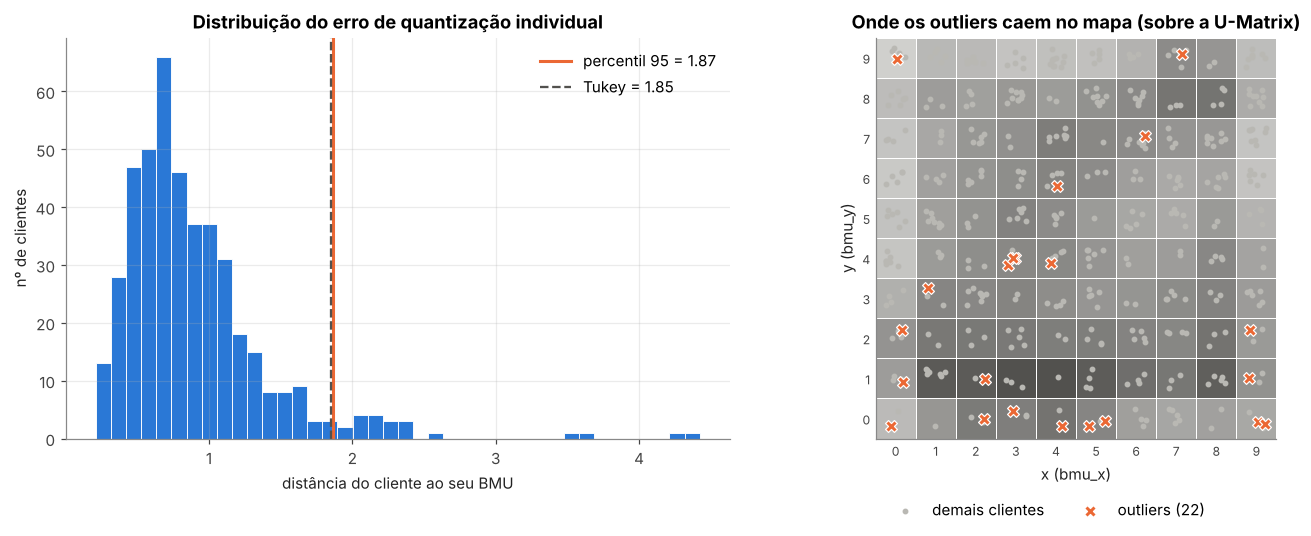

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
ax.hist(erro_quant, bins=40, color=AZUL, edgecolor="white", linewidth=0.6)
ax.axvline(p95, color=LARANJA, lw=2, label=f"percentil 95 = {p95:.2f}")
ax.axvline(tukey, color=CINZA, lw=1.5, ls="--", label=f"Tukey = {tukey:.2f}")
ax.set_title("Distribuição do erro de quantização individual"); ax.set_xlabel("distância do cliente ao seu BMU")
ax.set_ylabel("nº de clientes"); ax.legend(frameon=False)

ax = axes[1]
U = som.distance_map()
ax.pcolormesh(U.T, cmap=CINZAS, vmin=0, vmax=1, edgecolors="white", linewidth=0.6)
rng = np.random.default_rng(SEED)
pos = bmu + 0.5 + rng.uniform(-0.25, 0.25, size=bmu.shape)
ax.scatter(pos[~outlier, 0], pos[~outlier, 1], s=8, color="#b9b8b3", label="demais clientes", zorder=2)
ax.scatter(pos[outlier, 0], pos[outlier, 1], s=60, marker="X", color=LARANJA, edgecolor="white", linewidth=0.8,
           label=f"outliers ({outlier.sum()})", zorder=3)
eixo_mapa(ax, "Onde os outliers caem no mapa (sobre a U-Matrix)")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.12), ncol=2, frameon=False)
plt.tight_layout(); plt.savefig("figuras/04_outliers.png", bbox_inches="tight"); plt.show()

In [8]:
tab_out = df.loc[outlier, GASTOS + ["Canal"]].copy()
tab_out["erro_quant"] = erro_quant[outlier].round(2)
tab_out["bmu"] = [tuple(int(v) for v in b) for b in bmu[outlier]]
tab_out["cluster"] = cluster[outlier]
tab_out["menor_gasto"] = df.loc[outlier, GASTOS].min(axis=1)
tab_out["categoria_do_menor"] = df.loc[outlier, GASTOS].idxmin(axis=1)
tab_out = tab_out.sort_values("erro_quant", ascending=False)
display(tab_out)

print("Outliers com algum gasto ≤ 50:", (tab_out["menor_gasto"] <= 50).sum(), "de", len(tab_out))
print("Em qual categoria está o gasto mínimo:", tab_out["categoria_do_menor"].value_counts().to_dict())
print("Por canal:", tab_out["Canal"].value_counts().to_dict(), "| por cluster:", tab_out["cluster"].value_counts().sort_index().to_dict())
print(f"Nas duas linhas de baixo (y ≤ 1): {(bmu[outlier, 1] <= 1).sum()} de {outlier.sum()} outliers "
      f"(contra {(bmu[:, 1] <= 1).mean():.0%} de todos os clientes)")
um_cliente = np.argwhere(som.activation_response(X_scaled) == 1)
for x, y in um_cliente[:2]:
    i = np.where((bmu[:, 0] == x) & (bmu[:, 1] == y))[0][0]
    print(f"Cliente sozinho no neurônio ({x}, {y}): erro {erro_quant[i]:.2f}, acima de {(erro_quant < erro_quant[i]).mean():.0%} dos clientes")

# Comparação com os outliers IQR da Parte 1 (escala log)
L = np.log1p(df[GASTOS]); Q1, Q3 = L.quantile(0.25), L.quantile(0.75); IQR = Q3 - Q1
iqr_parte1 = ((L < Q1 - 1.5 * IQR) | (L > Q3 + 1.5 * IQR)).any(axis=1).values
print(f"Outliers IQR da Parte 1: {iqr_parte1.sum()} | em comum com os do SOM: {(iqr_parte1 & outlier).sum()} de {outlier.sum()}")

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Canal,erro_quant,bmu,cluster,menor_gasto,categoria_do_menor
75,20398,1137,3,4407,3,975,Horeca,4.42,"(0, 2)",0,3,Grocery
338,3,333,7021,15601,15,550,Horeca,4.22,"(2, 0)",0,3,Fresh
142,37036,7152,8253,2995,20,3,Horeca,3.64,"(0, 9)",0,3,Delicassen
154,622,55,137,75,7,8,Horeca,3.54,"(0, 0)",0,7,Detergents_Paper
95,3,2920,6252,440,223,709,Horeca,2.55,"(9, 0)",1,3,Fresh
128,140,8847,3823,142,1062,3,Horeca,2.36,"(4, 0)",1,3,Delicassen
358,759,18664,1660,6114,536,4100,Horeca,2.36,"(4, 6)",0,536,Detergents_Paper
402,26539,4753,5091,220,10,340,Horeca,2.34,"(3, 4)",0,10,Detergents_Paper
65,85,20959,45828,36,24231,1423,Varejo,2.27,"(9, 2)",1,36,Frozen
429,8607,1750,3580,47,84,2501,Horeca,2.25,"(3, 4)",0,47,Frozen


Outliers com algum gasto ≤ 50: 17 de 22
Em qual categoria está o gasto mínimo: {'Delicassen': 7, 'Detergents_Paper': 7, 'Fresh': 4, 'Frozen': 2, 'Grocery': 1, 'Milk': 1}
Por canal: {'Horeca': 19, 'Varejo': 3} | por cluster: {0: 13, 1: 7, 2: 2}
Nas duas linhas de baixo (y ≤ 1): 11 de 22 outliers (contra 16% de todos os clientes)
Cliente sozinho no neurônio (1, 0): erro 1.59, acima de 92% dos clientes
Cliente sozinho no neurônio (4, 1): erro 1.65, acima de 93% dos clientes
Outliers IQR da Parte 1: 42 | em comum com os do SOM: 15 de 22


**Leitura:**
- **O padrão dominante é "gasto quase zero numa categoria":** 17 dos 22 outliers têm algum gasto ≤ 50 por ano, contra uma mediana
  de centenas ou milhares. Exemplos: o cliente 75 compra 20.398 de Fresh, mas só **3** de Grocery e **3** de Detergents_Paper; o
  cliente 338 compra 15.601 de Frozen e **3** de Fresh. São clientes muito especializados, ou registros com erro, e vale checar com o negócio.
- **Há também o outro extremo:** o cliente 183 tem o maior gasto da base em Delicassen (47.943) e mais de 36 mil em Fresh, Milk
  e Frozen. O padrão de compra dele é comum, mas o volume é **grande demais** para qualquer neurônio.
- **19 dos 22 são Horeca.** Restaurantes e hotéis têm cardápios mais especializados e por isso deixam categorias inteiras de lado.
- **15 dos 22 coincidem com os outliers IQR da Parte 1** (que eram 42). O SOM é mais seletivo: ele marca quem é estranho na
  **combinação** das 6 variáveis, e não em uma só.
- **Metade dos outliers (11 de 22) cai nas duas linhas de baixo do mapa (y ≤ 1)**, onde estão só 16% dos clientes. É a faixa isolada
  pela fronteira mais escura da U-Matrix (Parte 3). Os dois clientes que ficaram sozinhos em neurônios dessa faixa, (1, 0) e (4, 1), não passam do corte,
  mas estão entre os 10% mais distantes dos seus BMUs. Os dois sinais (erro individual e neurônio isolado) apontam para a mesma região.

## 5. Figura-resumo para a apresentação
Clusters e atípicos no mesmo mapa.

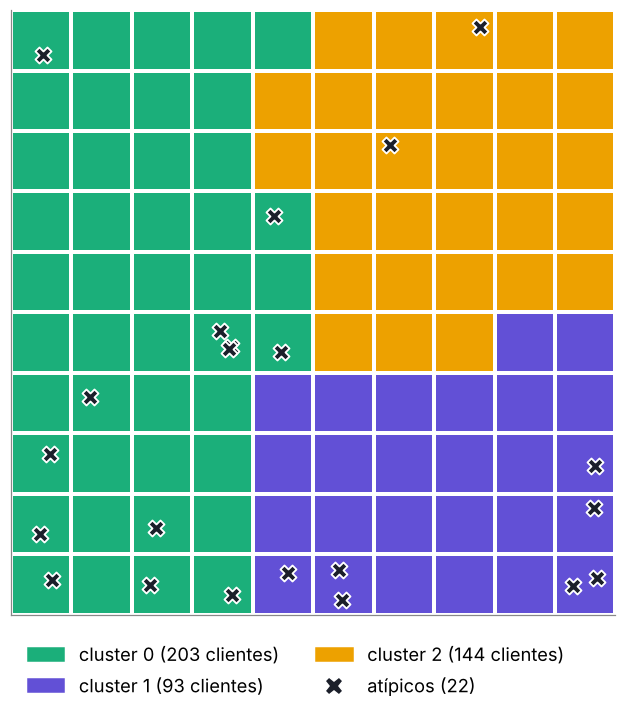

In [9]:
from matplotlib.lines import Line2D
fig, ax = plt.subplots(figsize=(6.6, 6.6))
ax.pcolormesh(cluster_neuronio.T, cmap=ListedColormap(COR_CLUSTER), vmin=-0.5, vmax=K - 0.5,
              edgecolors="white", linewidth=1.5)
rng = np.random.default_rng(SEED)
po = bmu[outlier] + 0.5 + rng.uniform(-0.28, 0.28, size=(int(outlier.sum()), 2))
ax.scatter(po[:, 0], po[:, 1], s=110, marker="X", color="#1B1F2A", edgecolor="white", linewidth=1.2, zorder=3)
ax.set_xlim(0, LADO); ax.set_ylim(0, LADO); ax.set_aspect("equal"); ax.grid(False)
ax.set_xticks([]); ax.set_yticks([])
alcas = [Patch(color=COR_CLUSTER[c], label=f"cluster {c} ({(cluster == c).sum()} clientes)") for c in range(K)]
alcas.append(Line2D([0], [0], marker="X", color="none", markerfacecolor="#1B1F2A", markeredgecolor="white",
                    markersize=12, label=f"atípicos ({int(outlier.sum())})"))
ax.legend(handles=alcas, loc="upper left", bbox_to_anchor=(0, -0.02), ncol=2, frameon=False, fontsize=12)
plt.tight_layout(); plt.savefig("figuras/04_resumo_slide.png", bbox_inches="tight"); plt.show()

## 6. Entrega: `dados/clusters.csv`
Uma linha por cliente, na mesma ordem da base (índice 0 a 439).

In [10]:
clusters = pd.DataFrame({
    "bmu_x": bmu[:, 0], "bmu_y": bmu[:, 1],
    "cluster": cluster,
    "erro_quant": erro_quant,
    "outlier": outlier,
})
clusters.to_csv("dados/clusters.csv", index=False)
print(clusters.shape); display(clusters.head())
print(clusters["cluster"].value_counts().sort_index().to_dict(), "| outliers:", clusters["outlier"].sum())

(440, 5)


,bmu_x,bmu_y,cluster,erro_quant,outlier
0,8,4,1,0.897207,False
1,8,6,2,0.405773,False
2,7,7,2,1.084007,False
3,3,8,0,0.731345,False
4,6,7,2,0.721139,False


{0: 203, 1: 93, 2: 144} | outliers: 22


## 7. Resumo da Parte 4 (para o relatório)
- **Método:** K-Means sobre os 100 vetores de pesos do SOM (duas etapas), com k testado de 2 a 6.
- **k = 3:** cotovelo em 3; o silhouette favorece k = 2 por só 0,027, e o k = 2 reproduz o canal. **Silhouettes baixos em todos os k
  (≤ 0,33)**: os dados são um contínuo, sem grupos bem separados.
- **Clusters (regiões contíguas do mapa):** 0 = esquerda, 203 clientes, 99% Horeca; 1 = canto inferior direito, 93 clientes,
  68% Varejo, quase sem frescos/congelados; 2 = canto superior direito, 144 clientes, misto, tudo acima da média.
- **Outliers:** 22 clientes com erro de quantização > percentil 95 (1,87). A cerca de Tukey dá 23 e concorda em 439 de 440 clientes,
  então o corte pega uma cauda real. 17 dos 22 têm gasto quase zero em alguma categoria, 19 são Horeca e 15 coincidem com o IQR da Parte 1.
- **Entrega:** `dados/clusters.csv` e as figuras `04_escolha_k.png`, `04_mapa_clusters.png` e `04_outliers.png`.